# Layer sweep (C): the P gate at every layer, Malinois

The Malinois half of the layer sweep. It uses the per-layer function CAVs fitted in `Layer Sweep A` / `B`
(`fcav_pool/fits_layers/all/<model>/`, one fit per TF on all ChIP sites) and nothing is refitted here. Models:
NT-v2 500M, HyenaDNA, DNABERT-2, GENA-LM.

**Section 1 (GPU).** P(bound | ref) of every Malinois motif occurrence at every fitted layer. One forward pass gives
all layers; each layer is projected on its own direction (`w_all`, `mu`, `sd` of that layer), exactly as
`P Gate with Five Models` 1.2 did for one layer. One file per (model, TF) in `malinois/p_layers/<model>/`, resumable;
`MODELS` can be cut to run one model per session. Check: at the layer used so far, P should rank the occurrences as
the earlier one-layer P (`malinois/p_<model>/`) did (the fits differ slightly: penalty chosen by 3-fold CV on all
sites instead of the median over 5 folds).

**Section 2 (CPU).** The same gate and evaluation as `P Gate with Five Models` 2.3, at every layer: per cell (HepG2,
K562, SK-N-SH) and variant set (all / active), Pearson of motifbreakR and the gain of the gate, p from the within-TF
shuffle (N2), AUROC gain for clear effects (|Δ| ≥ 2 SE). Tiers: all TFs, and TFs whose CAV has AUC ≥ 0.75 at that
layer. Line plots over relative depth.

Output: `malinois/p_layers/`, `layer_sweep/malinois_layer_summary.csv` and figures.

In [2]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0" "safetensors==0.4.5"
!pip install -q scikit-learn scipy pandas pyfaidx matplotlib
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


---
# Section 1 — P(bound | ref) of every Malinois occurrence at every layer *(GPU runtime)*

## 1.1 Settings

In [3]:
MODELS = ["nt500m", "hyenadna", "dnabert2", "genalm"]   # cut this list to run fewer models per session
CHUNK = 4000              # occurrences per forward batch group (keeps host memory small for TFs with many occurrences)

WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time, gc, sys, shutil
import numpy as np, pandas as pd
import torch
from scipy import stats
from pyfaidx import Fasta
from transformers import AutoTokenizer, AutoModel, AutoConfig, AutoModelForMaskedLM, AutoModelForCausalLM

C = json.load(open(f"{WORK_DIR}/config.json"))
POOL = f"{WORK_DIR}/fcav_pool"
MAL = f"{WORK_DIR}/malinois"
SWEEP = f"{POOL}/fits_layers/all"
REGISTRY = {
    "nt500m":   dict(hf="InstaDeepAI/nucleotide-transformer-v2-500m-multi-species", tok_map=("kmer", 6), causal=False, batch=32),
    "dnabert2": dict(hf="zhihan1996/DNABERT-2-117M",                                tok_map=("offsets",), causal=False, batch=32, out="dnabert2"),
    "genalm":   dict(hf="AIRI-Institute/gena-lm-bert-large-t2t",                    tok_map=("offsets",), causal=False, batch=32),
    "hyenadna": dict(hf="LongSafari/hyenadna-large-1m-seqlen-hf",                   tok_map=("char",), causal=True, batch=32, rc_mode="concat"),
}
OLD_LAYER = {"nt500m": 24, "hyenadna": 3, "dnabert2": 4, "genalm": 11}
BASE_WEIGHTED = False
BATCH = 32
WLEN, MOFF = C["window_len"], C["motif_offset"]
DEV = torch.device("cuda")
COMP = str.maketrans("ACGTN", "TGCAN")
rc = lambda s: s.translate(COMP)[::-1]


def fit_files(tag):
    d = f"{SWEEP}/{tag}"
    return {f[:-4]: f"{d}/{f}" for f in sorted(os.listdir(d)) if f.endswith(".npz") and not f.endswith(".part.npz")}


FILES = {t: fit_files(t) for t in MODELS}
LAYERS = {}
for t in MODELS:
    z = np.load(next(iter(FILES[t].values())))
    LAYERS[t] = [int(l) for l in z["layers"]]
    print(f"{t}: {len(FILES[t])} TFs fitted, layers {LAYERS[t][0]}..{LAYERS[t][-1]} ({len(LAYERS[t])})")
FIT_LAYERS = {}           # set by prepare() from LAYERS
LOCAL_FA = "/content/hg38.fa"
if not os.path.exists(LOCAL_FA):
    print("copying hg38 to local disk (~3 GB, one-off)...")
    shutil.copy(C["genome_fa"], LOCAL_FA)
    if os.path.exists(C["genome_fa"] + ".fai"):
        shutil.copy(C["genome_fa"] + ".fai", LOCAL_FA + ".fai")
GENOME = Fasta(LOCAL_FA, sequence_always_upper=True)
H = pd.read_csv(f"{MAL}/hits.csv")
U = H[~H["leak"]].drop_duplicates("uid")
print(f"{len(U):,} Malinois occurrences, {U['motif'].nunique()} TFs")

nt500m: 253 TFs fitted, layers 0..29 (30)
hyenadna: 251 TFs fitted, layers 0..9 (10)
dnabert2: 251 TFs fitted, layers 1..12 (12)
genalm: 251 TFs fitted, layers 0..24 (25)
copying hg38 to local disk (~3 GB, one-off)...
344,201 Malinois occurrences, 251 TFs


## 1.2 Tokens, models, readout (copied unchanged from `Layer Sweep A` 1.2)

In [4]:
def load_tokenizer(tag):
    spec = REGISTRY[tag]
    tokz = AutoTokenizer.from_pretrained(spec["hf"], trust_remote_code=True)
    tokz.padding_side = "right"          # several of these default to left (HyenaDNA)
    if tokz.pad_token is None:
        tokz.pad_token = tokz.eos_token if tokz.eos_token is not None else tokz.unk_token
    return tokz


def token_bases(spec, n):
    # (n, 2) base interval of each sequence token, for the arithmetic maps
    kind = spec["tok_map"][0]
    if kind == "kmer":
        k = spec["tok_map"][1]
        return np.stack([np.arange(n) * k, (np.arange(n) + 1) * k], 1)
    if kind == "char":
        return np.stack([np.arange(n), np.arange(n) + 1], 1)
    raise RuntimeError("offsets are resolved by the tokenizer, not here")


def encode(tokz, spec, seqs):
    # input_ids (B, T), attention mask (B, T), and per sequence: the positions of its sequence tokens in input_ids
    # and the base interval each one covers
    kind = spec["tok_map"][0]
    if kind == "offsets":
        assert tokz.is_fast, f"{spec['hf']} has no fast tokenizer, so offset mapping is unavailable"
        enc = tokz(seqs, return_tensors="pt", padding=True, return_offsets_mapping=True)
    else:
        enc = tokz(seqs, return_tensors="pt", padding=True)
    ids = enc["input_ids"]
    am = enc.get("attention_mask")
    if am is None:
        am = (ids != tokz.pad_token_id).long()
    amn = am.numpy()
    pos, spans = [], []
    if kind == "offsets":
        om = enc["offset_mapping"].numpy()
        for b in range(len(seqs)):
            keep = (om[b, :, 1] > om[b, :, 0]) & (amn[b] == 1)
            pos.append(np.flatnonzero(keep))
            spans.append(om[b, keep])
    else:
        for b in range(len(seqs)):
            sp = np.array(tokz.get_special_tokens_mask(ids[b].tolist(), already_has_special_tokens=True))
            p = np.flatnonzero((sp == 0) & (amn[b] == 1))
            pos.append(p)
            spans.append(token_bases(spec, len(p)))
        assert len({len(p) for p in pos}) == 1, f"{spec['hf']}: windows of equal length gave different token counts"
    return ids, am, pos, spans


def span_weights(bases, lo, hi):
    # per-token weight for the base interval [lo, hi)
    ov = np.minimum(bases[:, 1], hi) - np.maximum(bases[:, 0], lo)
    ov = np.clip(ov, 0, None).astype(np.float32)
    if not BASE_WEIGHTED:
        ov = (ov > 0).astype(np.float32)
    assert ov.sum() > 0, f"no token covers bases [{lo}, {hi})"
    return ov / ov.sum()


def load_model(tag):
    spec = REGISTRY[tag]
    # the class the checkpoint ships its own code for (NT-v2 has AutoModelForMaskedLM but no AutoModel)
    amap = getattr(AutoConfig.from_pretrained(spec["hf"], trust_remote_code=True), "auto_map", None) or {}
    cls = next((c for k, c in (("AutoModel", AutoModel), ("AutoModelForMaskedLM", AutoModelForMaskedLM),
                               ("AutoModelForCausalLM", AutoModelForCausalLM)) if k in amap), AutoModel)
    mdl = cls.from_pretrained(spec["hf"], trust_remote_code=True).to(DEV).eval()
    # DNABERT-2's triton flash-attention kernel does not compile on current triton; its code falls back to PyTorch
    for name in {type(m).__module__ for m in mdl.modules()}:
        mod = sys.modules.get(name)
        if mod is not None and getattr(mod, "flash_attn_qkvpacked_func", None) is not None:
            mod.flash_attn_qkvpacked_func = None
            print(f"{tag}: triton flash-attention disabled in {name.split('.')[-1]}; using PyTorch attention")
    if spec.get("out") == "dnabert2" and getattr(mdl, "pooler", None) is not None:
        mdl.pooler = None
    return mdl


POS, DEPTH, LOADED = {}, {}, {}


@torch.no_grad()
def hidden_stack(tag, model, ids, am):
    # one (layers, T_j, H) float tensor per sequence; only the layers in POS[tag] once prepare() has set it
    spec = REGISTRY[tag]
    if spec.get("out") == "dnabert2":
        # DNABERT-2 returns every encoder layer unpadded; one sequence at a time keeps the token order
        out = []
        for j in range(ids.shape[0]):
            t = ids[j][am[j].bool()][None].to(DEV)
            layers, _ = model(t, attention_mask=torch.ones_like(t), output_all_encoded_layers=True)
            S = torch.stack([x.reshape(t.shape[1], -1) for x in layers], 0).float()
            out.append(S[POS[tag]] if tag in POS else S)
        return out
    kw = {} if spec["causal"] else {"attention_mask": am.to(DEV)}
    hs = model(input_ids=ids.to(DEV), output_hidden_states=True, **kw).hidden_states
    if tag in POS:
        hs = [hs[i] for i in POS[tag]]
    S = torch.stack(hs, 1).float()
    return [S[j] for j in range(S.shape[0])]


PROBE = [GENOME[c][s - MOFF:s - MOFF + WLEN].seq for c, s in zip(U["chrom38"].iloc[:4], U["g38"].iloc[:4])]   # 4 Malinois windows to probe the token tiling


def prepare(tag):
    # load the model; from one forward pass: number of layers, token tiling, and where FIT_LAYERS sit in the stack
    spec = REGISTRY[tag]
    mdl = load_model(tag)
    tokz = LOADED.get(tag, {}).get("tokz") or load_tokenizer(tag)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    POS.pop(tag, None)
    ids, am, pos, spans = encode(tokz, spec, PROBE[:2])
    S = hidden_stack(tag, mdl, ids, am)
    for j, Sj in enumerate(S):
        assert Sj.ndim == 3 and int(pos[j].max()) < Sj.shape[1]
        b = spans[j]
        assert b[0, 0] == 0 and b[-1, 1] == WLEN and (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: tokens do not tile"
    nl = S[0].shape[0]
    lids = list(range(1, nl + 1)) if spec.get("out") == "dnabert2" else list(range(nl))   # DNABERT-2: no embedding layer
    DEPTH[tag] = lids[-1]
    FIT_LAYERS[tag] = sorted(set(lids if LAYERS[tag] == "all" else LAYERS[tag]) | {OLD_LAYER[tag]})
    miss = [l for l in FIT_LAYERS[tag] if l not in lids]
    assert not miss, f"{tag}: layers {miss} do not exist (ids {lids[0]}..{lids[-1]})"
    POS[tag] = [lids.index(l) for l in FIT_LAYERS[tag]]
    print(f"{tag}: {nl} layers (depth {DEPTH[tag]}), fitting {FIT_LAYERS[tag]}, hidden {S[0].shape[2]}, "
          f"{len(pos[0])} tokens for {WLEN} bp")
    del S
    return mdl


@torch.no_grad()
def readout(tag, model, seqs, lohi):
    # (n, layers, D): D = hidden, or 2 * hidden for a causal model (forward ‖ reverse complement)
    L = LOADED[tag]
    tokz, spec = L["tokz"], L["spec"]
    passes = [(seqs, lohi)]
    if spec["causal"]:
        passes.append(([rc(s) for s in seqs], [(WLEN - b, WLEN - a) for a, b in lohi]))
    bs = spec.get("batch", BATCH)
    parts = []
    for ss, lh in passes:
        out = None
        for i in range(0, len(ss), bs):
            chunk, lhc = ss[i:i + bs], lh[i:i + bs]
            ids, am, pos, spans = encode(tokz, spec, chunk)
            S = hidden_stack(tag, model, ids, am)
            if out is None:
                out = np.zeros((len(ss), S[0].shape[0], S[0].shape[2]), np.float16)
            for j in range(len(chunk)):
                w = torch.tensor(span_weights(spans[j], *lhc[j]), device=DEV)
                p = torch.tensor(pos[j], device=DEV)
                out[i + j] = (S[j][:, p] * w[None, :, None]).sum(1).half().cpu().numpy()
            del S
        parts.append(out)
    if len(parts) == 1:
        return parts[0]
    if spec.get("rc_mode", "concat") == "mean":
        return ((parts[0].astype(np.float32) + parts[1].astype(np.float32)) / 2).astype(np.float16)
    return np.concatenate(parts, 2)

## 1.3 P(bound | ref) at every layer

For each TF: the windows of its occurrences (600 bp, hg38, motif at bp 300, as before), the readout at every layer, and
for each layer `P = σ(((x − mu) / sd) · w + b)` with that layer's all-sites fit. Saved as one column per layer.

In [5]:
def p_all_layers(tag, m, windows, w_motif, mdl):
    z = np.load(FILES[tag][m], allow_pickle=False)
    assert [int(l) for l in z["layers"]] == FIT_LAYERS[tag], f"{tag} {m}: layers differ from the model's other fits"
    W, mu, sd = z["w_all"].astype(np.float64), z["mu"].astype(np.float64), z["sd"].astype(np.float64)
    out = []
    for i0 in range(0, len(windows), CHUNK):
        X = readout(tag, mdl, windows[i0:i0 + CHUNK], [(MOFF, MOFF + w_motif)] * len(windows[i0:i0 + CHUNK])).astype(np.float64)
        logit = np.einsum("nld,ld->nl", (X - mu[None]) / sd[None], W[:, :-1]) + W[None, :, -1]
        out.append(1 / (1 + np.exp(-logit)))
        del X
    return np.vstack(out)


t_all = time.time()
for tag in MODELS:
    OUTP = f"{MAL}/p_layers/{tag}"
    os.makedirs(OUTP, exist_ok=True)
    todo = [(m, g) for m, g in U.groupby("motif") if m in FILES[tag] and not os.path.exists(f"{OUTP}/{m}.csv")]
    n_left = sum(len(g) for _, g in todo)
    print(f"\n=== {tag}: {len(todo)} TFs, {n_left:,} occurrences to do", flush=True)
    if not todo:
        continue
    mdl = prepare(tag)
    t_m, done = time.time(), 0
    for k, (m, g) in enumerate(todo):
        w = int(g["b"].iloc[0] - g["a"].iloc[0])
        wins = [GENOME[c][s - MOFF:s - MOFF + WLEN].seq for c, s in zip(g["chrom38"], g["g38"])]
        assert all(len(x) == WLEN and "N" not in x for x in wins)
        P = p_all_layers(tag, m, wins, w, mdl)
        df = pd.DataFrame(P.astype(np.float32), columns=[f"L{l}" for l in FIT_LAYERS[tag]])
        df.insert(0, "uid", g["uid"].values)
        df.to_csv(f"{OUTP}/{m}.part.csv", index=False)
        os.replace(f"{OUTP}/{m}.part.csv", f"{OUTP}/{m}.csv")
        done += len(g)
        el = time.time() - t_m
        if k % 10 == 0 or k == len(todo) - 1:
            print(f"[{tag} {k + 1}/{len(todo)}] {m:10s} {len(g):6,} occurrences  [{el / 60:.1f} min; ~{el / done * (n_left - done) / 60:.0f} min left]", flush=True)
    del mdl; gc.collect(); torch.cuda.empty_cache()
print(f"\ndone [{(time.time() - t_all) / 60:.1f} min]")


=== nt500m: 251 TFs, 344,201 occurrences to do


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

esm_config.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/InstaDeepAI/nucleotide-transformer-v2-500m-multi-species:
- esm_config.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_esm.py: 0.00B [00:00, ?B/s]

... (87 outputs left out)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modelin

[genalm 241/251] ZNF841      1,081 occurrences  [62.9 min; ~3 min left]


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modelin

[genalm 251/251] Zfx         2,849 occurrences  [65.6 min; ~0 min left]

done [295.2 min]


## 1.4 Check against the earlier one-layer P

At the layer used so far: Spearman between the new P and the earlier `malinois/p_<model>/` P over all occurrences,
and per TF (median). Expected close to 1; the two fits differ only in how the penalty was chosen.

In [6]:
rd = lambda d: pd.concat([pd.read_csv(f"{d}/{f}") for f in sorted(os.listdir(d)) if f.endswith(".csv") and not f.endswith(".part.csv")])
for tag in MODELS:
    d_old, d_new = f"{MAL}/p_{tag}", f"{MAL}/p_layers/{tag}"
    if not (os.path.isdir(d_old) and os.path.isdir(d_new)):
        print(f"{tag}: no earlier P to compare with"); continue
    old = rd(d_old).set_index("uid")["P"]
    new = rd(d_new).set_index("uid")[f"L{OLD_LAYER[tag]}"]
    j = pd.concat([old, new], axis=1, join="inner").dropna()
    j["motif"] = U.set_index("uid")["motif"].reindex(j.index).values
    per = j.groupby("motif").apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0] if len(g) > 5 else np.nan)
    print(f"{tag} L{OLD_LAYER[tag]}: {len(j):,} occurrences; Spearman overall {stats.spearmanr(j.iloc[:, 0], j.iloc[:, 1])[0]:.3f}, "
          f"per TF median {per.median():.3f} (10th pct {per.quantile(.1):.3f})")

/tmp/ipykernel_449/2971480362.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = j.groupby("motif").apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0] if len(g) > 5 else np.nan)


nt500m L24: 344,201 occurrences; Spearman overall 0.985, per TF median 1.000 (10th pct 0.969)


/tmp/ipykernel_449/2971480362.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = j.groupby("motif").apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0] if len(g) > 5 else np.nan)


hyenadna L3: 344,201 occurrences; Spearman overall 0.989, per TF median 1.000 (10th pct 0.972)


/tmp/ipykernel_449/2971480362.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = j.groupby("motif").apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0] if len(g) > 5 else np.nan)


dnabert2 L4: 344,201 occurrences; Spearman overall 0.994, per TF median 1.000 (10th pct 0.985)
genalm L11: 344,201 occurrences; Spearman overall 0.993, per TF median 1.000 (10th pct 0.977)


/tmp/ipykernel_449/2971480362.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = j.groupby("motif").apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0] if len(g) > 5 else np.nan)


In [7]:
from google.colab import runtime
runtime.unassign()

---
# Section 2 — the gate at every layer, Malinois *(CPU runtime)*

## 2.1 Shared (copied from `Layer Sweep A` 2.1)

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from google.colab import drive
drive.mount('/content/drive')
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, re, time
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

MAL = f"{WORK_DIR}/malinois"
POOL = f"{WORK_DIR}/fcav_pool"
OUT = f"{WORK_DIR}/layer_sweep"
os.makedirs(OUT, exist_ok=True)
MODELS = ["nt500m", "hyenadna", "dnabert2", "genalm"]
LAYER_OF = {"nt500m": 24, "dnabert2": 4, "genalm": 11, "hyenadna": 3}      # the layer used so far (for the check)
N_PERM = 100
pd.set_option("display.width", 250)
fmt = lambda x: f"{x:+.3f}"


_CACHE = {}


def load_fit(model, L, version="all"):
    # per TF: held-out ChIP AUC at layer L, and the out-of-fold P(bound) of every Kircher hit
    # (each file is read once per (version, model); all layers are kept in memory)
    if (version, model) not in _CACHE:
        d, Z = f"{SWEEP}/{version}/{model}", {}
        for f in sorted(os.listdir(d)):
            if f.endswith(".npz") and not f.endswith(".part.npz"):
                z = np.load(f"{d}/{f}", allow_pickle=False)
                Z[f[:-4]] = ([int(l) for l in z["layers"]], np.asarray(z["auc"]), z["hit_region"].astype(int),
                             z["hit_id"].astype(int), np.asarray(z["prob_hit"]))
        _CACHE[version, model] = Z
    auc, kp = {}, {}
    for m, (lids, a, hr, hid, ph) in _CACHE[version, model].items():
        li = lids.index(L)
        auc[m] = float(a[li])
        for r, h, p in zip(hr, hid, ph[:, li]):
            kp[r, h] = float(p)
    return auc, kp


def layers_of(model, version="all"):
    d = f"{SWEEP}/{version}/{model}"
    f = next(f for f in sorted(os.listdir(d)) if f.endswith(".npz") and not f.endswith(".part.npz"))
    z = np.load(f"{d}/{f}", allow_pickle=False)
    return [int(l) for l in z["layers"]], int(z["n_layers"])


SWEEP = f"{POOL}/fits_layers"
VERSIONS = [v for v in sorted(os.listdir(SWEEP)) if os.path.isdir(f"{SWEEP}/{v}")]
DONE = {v: [m for m in MODELS if os.path.isdir(f"{SWEEP}/{v}/{m}")] for v in VERSIONS}
print("fit versions and models found:", DONE)


def pear(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if a.std() == 0 or b.std() == 0:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def auroc(lab, s):
    lab = np.asarray(lab, bool)
    return roc_auc_score(lab, s) if 0 < lab.sum() < len(lab) else np.nan


def tf_pct(x, g):
    o = np.lexsort((x, g))
    gs = g[o]
    st = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    cnt = np.diff(np.r_[st, len(gs)])
    q = np.empty(len(x)); q[o] = (np.arange(len(gs)) - np.repeat(st, cnt) + 0.5) / np.repeat(cnt, cnt)
    return q


def pick(v, grp, n):
    out = np.zeros(n)
    if len(v):
        o = np.lexsort((-np.abs(v), grp))
        f = o[np.r_[True, grp[o][1:] != grp[o][:-1]]]
        out[grp[f]] = v[f]
    return out


def gate(T, p, n):
    return pick(T["ad"] * tf_pct(p, T["tf"]), T["grp"], n)


def shuffle_tf(T, rng):
    o = np.lexsort((rng.random(len(T["tf"])), T["tf"]))
    out = np.empty(len(o)); out[np.argsort(T["tf"], kind="stable")] = T["p"][o]
    return out
OLD_LAYER_OF = LAYER_OF


Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fit versions and models found: {'all': ['nt500m', 'hyenadna', 'dnabert2', 'genalm']}


## 2.2 Every model, every layer

Copied from `P Gate with Five Models` 2.3; the only change is that P and the CAV AUC are those of one layer at a time.
NT-v2 500M at L24, all TFs, active variants should come out close to the earlier run (HepG2 0.139 → 0.160, K562
0.124 → 0.153, SK-N-SH 0.107 → 0.130).

In [2]:
CELLS3 = ["HepG2", "K562", "SKNSH"]
TIERS = [("all TFs", 0.0), ("AUC >= 0.75", 0.75)]
ACTIVE_MIN, Z_CLEAR = 1.0, 2.0
MAL = f"{WORK_DIR}/malinois"
V = pd.read_csv(f"{MAL}/variants.csv.gz", index_col="vi", dtype={"chrom": str}, low_memory=False)
H = pd.read_csv(f"{MAL}/hits.csv")
H = H[~H["leak"]][["vi", "uid", "motif"]]
CALLS = pd.read_csv(f"{MAL}/calls.csv")
rd = lambda d: pd.concat([pd.read_csv(f"{d}/{f}") for f in sorted(os.listdir(d)) if f.endswith(".csv") and not f.endswith(".part.csv")])
MDONE = [m for m in MODELS if os.path.isdir(f"{MAL}/p_layers/{m}")
         and len([f for f in os.listdir(f"{MAL}/p_layers/{m}") if f.endswith(".csv") and not f.endswith(".part.csv")]) >= 240]
print("Malinois per-layer P available for:", MDONE)
assert MDONE, "No per-layer P found in malinois/p_layers/. Run Section 1 on a GPU runtime first."

MROWS = []
t0 = time.time()
for model in MDONE:
    PL = rd(f"{MAL}/p_layers/{model}").set_index("uid")
    lids, depth = layers_of(model)
    for L in lids:
        auc, _ = load_fit(model, L)
        hp = H.assign(P=PL[f"L{L}"].reindex(H["uid"]).values).dropna(subset=["P"])
        CM = CALLS.merge(hp.groupby(["vi", "motif"])["P"].max().reset_index(), on=["vi", "motif"])
        CM["auc"] = CM["motif"].map(auc)
        for tier, thr in TIERS:
            Lc = CM[CM["auc"] >= thr].sort_values(["vi", "motif"]).reset_index(drop=True)
            VI = np.unique(Lc["vi"].values)
            T = dict(ad=Lc["alleleDiff"].values, tf=pd.factorize(Lc["motif"])[0], grp=np.searchsorted(VI, Lc["vi"].values), p=Lc["P"].values)
            n = len(VI)
            Y = {c: V.loc[VI, f"d_{c}"].values for c in CELLS3}
            CLR = {c: np.abs(Y[c]) / V.loc[VI, f"se_{c}"].values >= Z_CLEAR for c in CELLS3}
            SETS = {(c, s): np.isfinite(Y[c]) & ((V.loc[VI, f"act_{c}"].values >= ACTIVE_MIN) if s == "active" else True)
                    for c in CELLS3 for s in ("all", "active")}
            mb = pick(T["ad"], T["grp"], n)
            gt = gate(T, T["p"], n)
            rng = np.random.default_rng(7)
            nulls = [gate(T, shuffle_tf(T, rng), n) for _ in range(N_PERM)]
            for (c, s), m in SETS.items():
                y = Y[c][m]
                r_mb, r_gt = pear(mb[m], y), pear(gt[m], y)
                MROWS.append({"model": model, "layer": L, "depth": L / depth, "tier": tier, "cell": c, "variants": s,
                              "TFs": int(Lc["motif"].nunique()), "n": int(m.sum()), "mean ChIP AUC": float(np.mean(list(auc.values()))),
                              "motifbreakR": r_mb, "gate": r_gt, "gain": r_gt - r_mb,
                              "p N2": float(np.mean([pear(g_[m], y) >= r_gt for g_ in nulls])),
                              "AUROC gain": auroc(CLR[c][m], np.abs(gt[m])) - auroc(CLR[c][m], np.abs(mb[m]))})
    print(f"{model}: {len(lids)} layers [{(time.time() - t0) / 60:.1f} min]", flush=True)
MLS = pd.DataFrame(MROWS)
MLS.to_csv(f"{OUT}/malinois_layer_summary.csv", index=False)

chk = MLS[(MLS.model == "nt500m") & (MLS.layer == 24) & (MLS.tier == "all TFs") & (MLS.variants == "active")]
if len(chk):
    print("\ncheck NT-v2 500M L24, all TFs, active: " + ", ".join(f"{c} {a:.3f} -> {b:.3f}" for c, a, b in zip(chk.cell, chk.motifbreakR, chk.gate))
          + "  (was HepG2 0.139 -> 0.160, K562 0.124 -> 0.153, SKNSH 0.107 -> 0.130)")
for tier, _ in TIERS:
    t = MLS[(MLS.tier == tier) & (MLS.variants == "active")].copy()
    t["cell_"] = [f"{g:+.3f} (p {p:.2f})" for g, p in zip(t.gain, t["p N2"])]
    for c in CELLS3:
        print(f"\n=== {tier}, {c}, active variants: gain of the gate over motifbreakR (p N2)\n"
              + t[t.cell == c].pivot(index="layer", columns="model", values="cell_").fillna("").to_string())

Malinois per-layer P available for: ['nt500m', 'hyenadna', 'dnabert2', 'genalm']
nt500m: 30 layers [8.5 min]
hyenadna: 10 layers [11.2 min]
dnabert2: 12 layers [14.6 min]
genalm: 25 layers [21.8 min]

check NT-v2 500M L24, all TFs, active: HepG2 0.139 -> 0.158, K562 0.124 -> 0.152, SKNSH 0.107 -> 0.129  (was HepG2 0.139 -> 0.160, K562 0.124 -> 0.153, SKNSH 0.107 -> 0.130)

=== all TFs, HepG2, active variants: gain of the gate over motifbreakR (p N2)
model         dnabert2           genalm         hyenadna           nt500m
layer                                                                    
0                       +0.016 (p 0.07)  +0.009 (p 0.54)  +0.021 (p 0.00)
1      +0.014 (p 0.05)  +0.016 (p 0.04)  +0.019 (p 0.01)  +0.022 (p 0.00)
2      +0.014 (p 0.10)  +0.014 (p 0.07)  +0.017 (p 0.02)  +0.019 (p 0.01)
3      +0.018 (p 0.01)  +0.011 (p 0.29)  +0.021 (p 0.00)  +0.019 (p 0.01)
4      +0.018 (p 0.05)  +0.014 (p 0.05)  +0.018 (p 0.00)  +0.018 (p 0.01)
5      +0.011 (p 0.22)  +0.0

## 2.3 Line plots over relative depth

Active variants. Panels: mean ChIP AUC of the CAVs, then the gate's Pearson gain in HepG2, K562 and SK-N-SH. Filled
markers: p N2 < 0.05. The layer used so far is circled.

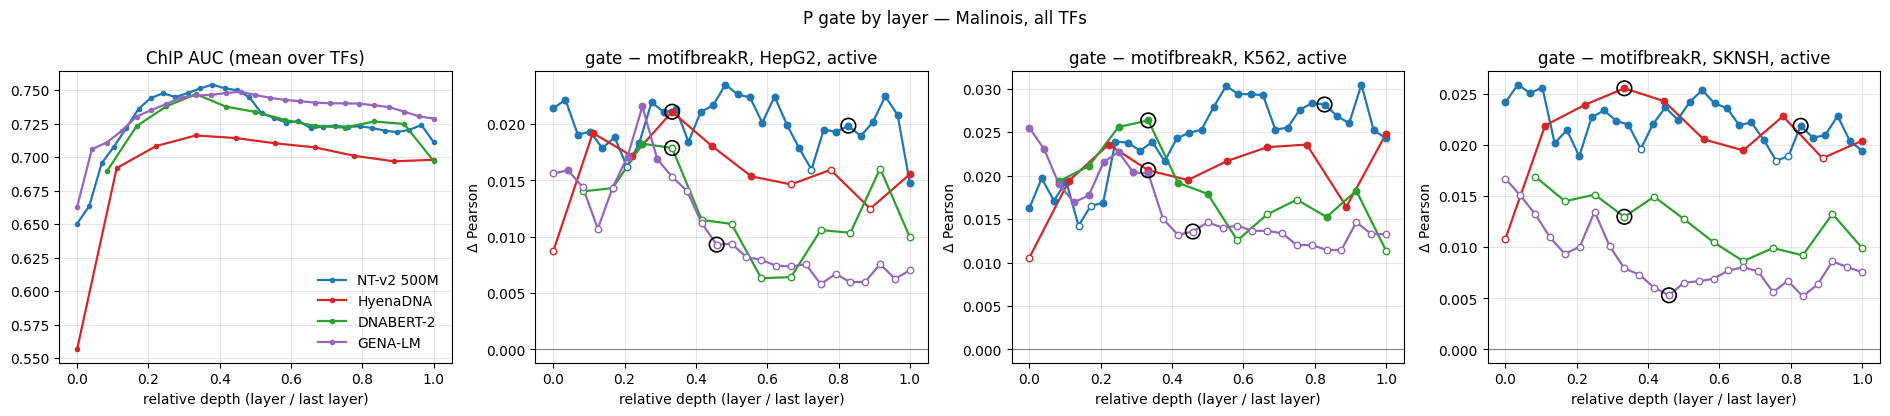

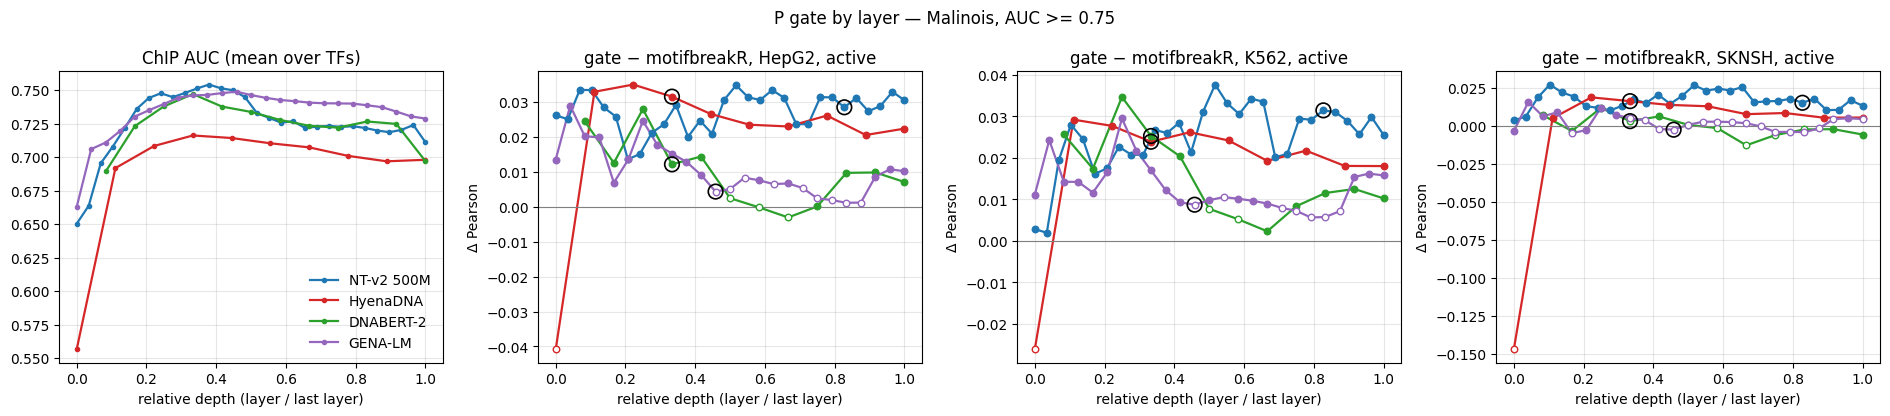

In [3]:
import matplotlib.pyplot as plt
COL = {"nt500m": "#1f77b4", "hyenadna": "#d62728", "dnabert2": "#2ca02c", "genalm": "#9467bd"}
NAME = {"nt500m": "NT-v2 500M", "hyenadna": "HyenaDNA", "dnabert2": "DNABERT-2", "genalm": "GENA-LM"}
for tier, _ in TIERS:
    t = MLS[(MLS.tier == tier) & (MLS.variants == "active")]
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
    for model in MDONE:
        u0 = t[(t.model == model) & (t.cell == "HepG2")].sort_values("depth")
        ax[0].plot(u0.depth, u0["mean ChIP AUC"], "-o", ms=3, color=COL[model], label=NAME[model], lw=1.6)
        for k, c in enumerate(CELLS3, start=1):
            u = t[(t.model == model) & (t.cell == c)].sort_values("depth")
            sig = (u["p N2"] < 0.05).values
            ax[k].plot(u.depth, u.gain, "-", color=COL[model], lw=1.6)
            ax[k].scatter(u.depth[sig], u.gain[sig], color=COL[model], s=22, zorder=3)
            ax[k].scatter(u.depth[~sig], u.gain[~sig], facecolor="white", edgecolor=COL[model], s=22, zorder=3)
            o = u[u.layer == LAYER_OF[model]]
            ax[k].scatter(o.depth, o.gain, facecolor="none", edgecolor="black", s=110, lw=1.2, zorder=4)
    ax[0].set_title("ChIP AUC (mean over TFs)")
    for k, c in enumerate(CELLS3, start=1):
        ax[k].set_title(f"gate − motifbreakR, {c}, active")
        ax[k].axhline(0, color="grey", lw=.8)
        ax[k].set_ylabel("Δ Pearson")
    for a_ in ax:
        a_.set_xlabel("relative depth (layer / last layer)")
        a_.grid(alpha=.3)
    ax[0].legend(frameon=False)
    fig.suptitle(f"P gate by layer — Malinois, {tier}")
    fig.tight_layout()
    fig.savefig(f"{OUT}/malinois_layer_sweep_{tier.replace(' ', '').replace('>=', 'ge')}.png", dpi=160)
    plt.show()

## End

Outputs: `malinois/p_layers/<model>/<TF>.csv` (one P column per layer); `layer_sweep/malinois_layer_summary.csv` and
the figures.